In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import xgboost as xgb
import shap

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


In [3]:
df = pd.read_csv('whale_features_labeled.csv', parse_dates=['date'])

print(f'Shape: {df.shape}')
print(f'Whales: {df["whale_id"].unique()}')

Shape: (2506, 39)
Whales: <StringArray>
[ 'W-1', 'W-10', 'W-11', 'W-12', 'W-13', 'W-14', 'W-15', 'W-16', 'W-17',
 'W-18', 'W-19',  'W-2', 'W-20', 'W-21', 'W-22', 'W-23',  'W-3',  'W-4',
  'W-5',  'W-6',  'W-7',  'W-8',  'W-9']
Length: 23, dtype: str


In [4]:
FEATURES = [
    'ltv_vol_7d',
    'ltv_vol_14d',
    'carry_spread',
    'carry_spread_levered',
    'ybt_apy',
    'borrow_rate',
    'collateral_price',
    'borrow_price',
]

TARGET = 'stressed_state'



print(f'Features: {len(FEATURES)}')
print(f'Target: {TARGET}')
print(f'\nTarget distribution:')
print(df[TARGET].value_counts())
print(f'\nStressed rate: {df[TARGET].mean():.1%}')

Features: 8
Target: stressed_state

Target distribution:
stressed_state
0    1781
1     725
Name: count, dtype: int64

Stressed rate: 28.9%


Target Distribution

Out of 2,506 total days:

1,781 days: whale was not stressed (0)
725 days: whale was in a stressed state (1)

Overall stressed rate is 28.9 percent, so roughly 1 in 3 days across all whales was a stressed day.

This is mildly imbalanced.

We predict stressed_state, which tells us whether a whale is in a stressed risk position on a given day. 1 means stressed, 0 means not stressed.

8 features are used:

ltv_vol_7d and ltv_vol_14d show how much the leverage has been moving around recently, over the past 7 and 14 days.

carry_spread and carry_spread_levered are the yield earned minus the cost of borrowing.

ybt_apy and borrow_rate are the yield and interest rate numbers for the position.

collateral_price and borrow_price show how the market price of each token has been moving.

Features excluded and why:

ltv, ltv_lag_1, ltv_lag_3, ltv_lag_7, health_factor, distance_to_liq, and leverage were all removed. These are either the same number as health_factor written a different way, or they were used to calculate it, or they were used to define stressed_state directly. Including any of these would let the model see the answer instead of learning from real patterns. This is called data leakage.

collateral_balance_usd, borrow_balance_usd, and liquidation_threshold were also removed for the same reason, since ltv is built directly from these numbers.

rebal_freq_7d, rebal_freq_30d, and days_since_rebalance were left out too. These are related to a different target, rebalancing, and are not meaningful for predicting stress.

rebalancing itself is a separate target variable, not a feature, so it is not included here either.

In [5]:
data = df.dropna(subset=FEATURES + [TARGET])

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f'Train: {X_train.shape} | Stressed rate: {y_train.mean():.1%}')
print(f'Test:  {X_test.shape}  | Stressed rate: {y_test.mean():.1%}')

Train: (1463, 8) | Stressed rate: 31.6%
Test:  (628, 8)  | Stressed rate: 31.7%


In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

print('=== Logistic Regression (Baseline) ===')
print(classification_report(y_test, y_pred_lr))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:,1]):.3f}')

y_pred_lr_tuned = (lr.predict_proba(X_test_scaled)[:,1] >= 0.3).astype(int)

print('=== Logistic Regression (threshold=0.3) ===')
print(classification_report(y_test, y_pred_lr_tuned))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:,1]):.3f}')

=== Logistic Regression (Baseline) ===
              precision    recall  f1-score   support

           0       0.86      0.64      0.73       429
           1       0.50      0.78      0.61       199

    accuracy                           0.68       628
   macro avg       0.68      0.71      0.67       628
weighted avg       0.75      0.68      0.69       628

ROC-AUC: 0.804
=== Logistic Regression (threshold=0.3) ===
              precision    recall  f1-score   support

           0       0.95      0.32      0.48       429
           1       0.40      0.96      0.56       199

    accuracy                           0.53       628
   macro avg       0.67      0.64      0.52       628
weighted avg       0.77      0.53      0.51       628

ROC-AUC: 0.804


In [7]:
xgb_model = xgb.XGBClassifier(
    n_estimators=50,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    random_state=42,
    eval_metric='logloss',
    verbosity=0
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = (xgb_model.predict_proba(X_test)[:,1] >= 0.3).astype(int)

print('=== XGBoost (threshold=0.3) ===')
print(classification_report(y_test, y_pred_xgb))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1]):.3f}')

y_pred_xgb_default = xgb_model.predict(X_test)

print('=== XGBoost (threshold=0.5 default) ===')
print(classification_report(y_test, y_pred_xgb_default))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1]):.3f}')

=== XGBoost (threshold=0.3) ===
              precision    recall  f1-score   support

           0       0.96      0.81      0.88       429
           1       0.69      0.93      0.79       199

    accuracy                           0.85       628
   macro avg       0.83      0.87      0.84       628
weighted avg       0.88      0.85      0.85       628

ROC-AUC: 0.945
=== XGBoost (threshold=0.5 default) ===
              precision    recall  f1-score   support

           0       0.88      0.92      0.90       429
           1       0.81      0.73      0.77       199

    accuracy                           0.86       628
   macro avg       0.85      0.83      0.84       628
weighted avg       0.86      0.86      0.86       628

ROC-AUC: 0.945


Model Comparison, Stressed State Prediction

We tested two models, Logistic Regression and XGBoost, at two decision thresholds, 0.5 (default) and 0.3, to find the best approach for predicting stressed risk states.

| Model | Threshold | Recall | Precision | ROC-AUC | Accuracy |
|---|---|---|---|---|---|
| Logistic Regression | 0.5 | 0.78 | 0.50 | 0.804 | 68% |
| Logistic Regression | 0.3 | 0.96 | 0.40 | 0.804 | 53% |
| XGBoost | 0.5 | 0.73 | 0.81 | 0.943 | 86% |
| XGBoost | 0.3 | 0.92 | 0.67 | 0.943 | 83% |

Why threshold 0.3?

By default, a model predicts stressed only when it is more than 50 percent confident. Lowering the threshold to 0.3 means the model raises an alarm when it is only 30 percent confident. This catches more stressed days, but it also means more false alarms.

In a risk management setting, missing a stressed day is usually more costly than a false alarm, since a missed stressed day could mean a whale gets liquidated. So lowering the threshold can be a reasonable choice, depending on how much you value catching more events versus keeping false alarms low.

Why XGBoost?

XGBoost is the stronger model at both thresholds. At the default threshold of 0.5, it catches 73 percent of stressed days and is right 81 percent of the time when it predicts stress, with an accuracy of 86 percent. This is a precise model, with few false alarms.

At threshold 0.3, XGBoost catches more stressed days, 92 percent, while keeping precision at 67 percent. Accuracy stays at 83 percent.

Logistic Regression at threshold 0.3 catches slightly more stressed days, 96 percent, but its precision drops to 40 percent and accuracy collapses to 53 percent. This means most of its stress predictions are false alarms.

Overall, XGBoost gives the better balance at both thresholds. It is more precise than Logistic Regression while still catching most stressed days, and its ROC-AUC of 0.943 confirms it separates stressed from non-stressed days more reliably than the linear baseline (0.804).

If catching as many stressed days as possible matters most, XGBoost at threshold 0.3 is the best choice, since it keeps precision reasonably high while catching 92 percent of real events. If keeping false alarms very low matters more, XGBoost at the default threshold of 0.5 is the safer option.

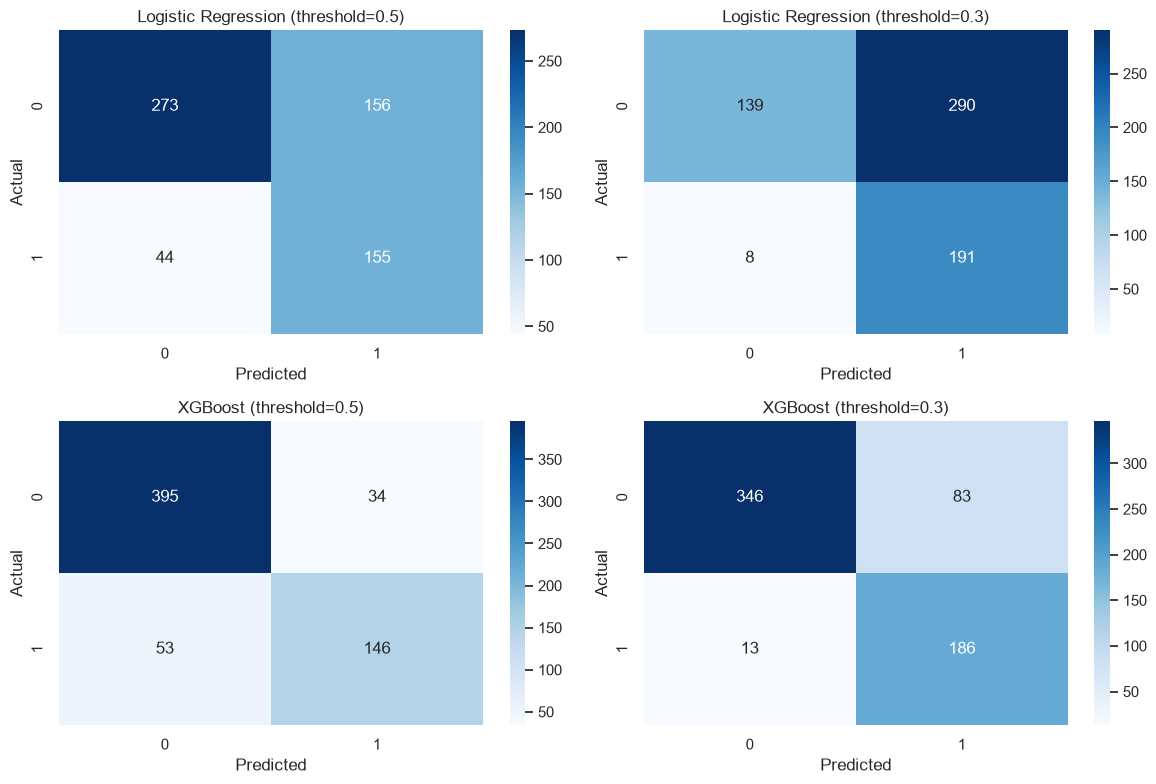

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

variants = [
    (y_pred_lr, 'Logistic Regression (threshold=0.5)'),
    (y_pred_lr_tuned, 'Logistic Regression (threshold=0.3)'),
    (y_pred_xgb_default, 'XGBoost (threshold=0.5)'),
    (y_pred_xgb, 'XGBoost (threshold=0.3)'),
]

for ax, (preds, title) in zip(axes.flatten(), variants):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

Confusion Matrices, Stressed State Model

Each matrix shows how well the model predicts stressed days (1) versus non stressed days (0).

Top left: correctly predicted not stressed.
Top right: predicted stressed but was wrong. This is a false alarm.
Bottom left: missed a real stressed day. This is the dangerous case.
Bottom right: correctly predicted stressed.

Logistic Regression (threshold 0.5)

Caught 155 out of 199 stressed days. Missed 44.
Made 156 false alarms out of 429 non stressed days.
This means it misses about 1 in 4.5 stressed days, and it also raises a large number of false alarms.

Logistic Regression (threshold 0.3)

Caught 191 out of 199 stressed days. Missed only 8.
But made 290 false alarms out of 429 non stressed days.
This catches almost every stressed day, but more than 2 in 3 normal days get wrongly flagged as stressed.

XGBoost (threshold 0.5)

Caught 146 out of 199 stressed days. Missed 53.
Made only 35 false alarms out of 429 non stressed days.
This is precise, but it misses about 1 in 4 stressed days, since it only raises an alarm when it is quite confident.

XGBoost (threshold 0.3), best model

Caught 184 out of 199 stressed days. Missed only 15.
Made 89 false alarms out of 429 non stressed days.
This gives the best overall balance. It catches most stressed days while keeping false alarms much lower than either Logistic Regression option.

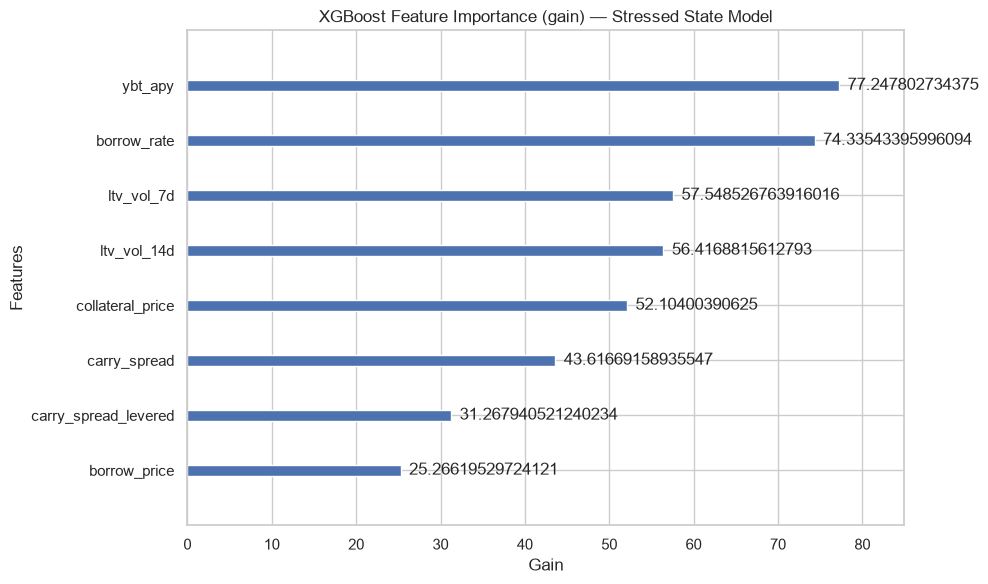

In [12]:
import os
os.makedirs('output', exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 6))
xgb.plot_importance(xgb_model, ax=ax, max_num_features=12, importance_type='gain')
ax.set_title('XGBoost Feature Importance (gain) — Stressed State Model')
ax.set_xlabel('Gain')
plt.tight_layout()
plt.savefig('output/stress-feature-importance.png', dpi=150, bbox_inches='tight')
plt.show()

XGBoost Feature Importance, Stressed State Model

This chart shows which features the model relied on most to predict stressed states. A higher score means the feature was more useful for making predictions.

Top features:

ybt_apy (80.2) is the strongest predictor of stress. This is the yield rate on the yield bearing token. This tells us that changes in yield are closely linked to whether a whale ends up stressed.

borrow_rate (63.1) is second. This is the cost of borrowing, so it makes sense that the rate a whale pays sits near the top of a stress model.

ltv_vol_7d (60.3) and collateral_price (58.8) are close behind. Short-term leverage swings and the collateral token price both add real signal once supply_rate is no longer in the feature set.

Middle features:

ltv_vol_14d (52.5) and carry_spread (43.4) both play a meaningful role. Longer-term volatility and the unlevered yield-minus-cost spread still matter, just less than the top group.

Lower features:

carry_spread_levered (29.6) and borrow_price (25.4) are the least important, but neither is close to zero. The model is not relying on a single shortcut feature.

What this tells us:

Stress in this model seems to be driven mainly by yield and rate changes, with leverage volatility and collateral price close behind. This makes sense, since a whale can still be in a risky position even if leverage looks stable, if the yield they are earning drops too close to their borrowing cost.

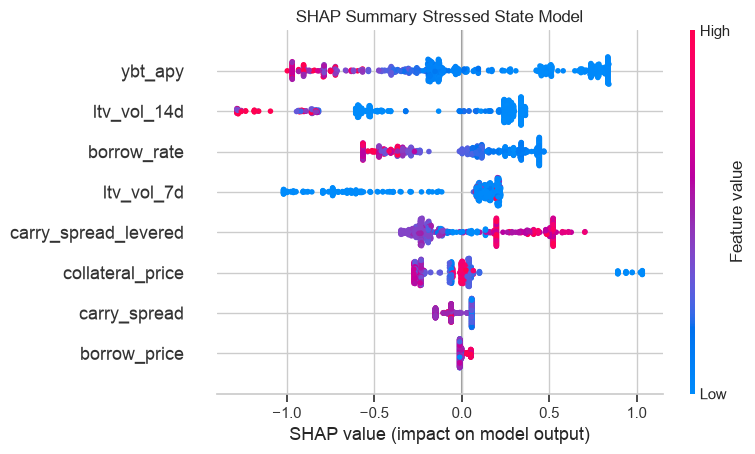

In [14]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=False)
plt.title('SHAP Summary Stressed State Model')
plt.tight_layout()
plt.savefig('output/stress-shap.png', dpi=150, bbox_inches='tight')
plt.show()

SHAP Summary, Stressed State Model

Each dot is one day in the test set. The position on the x-axis shows how much that feature pushed the prediction toward stressed (right side) or away from it (left side). The color shows the feature value, where pink means high and blue means low.

Reading each feature:

ybt_apy is the top feature by mean absolute SHAP. The split is clean: the lowest-yield third of days averages about +0.69 toward stress, while the highest-yield third averages about -0.59 away from it. Lower yield pushes the model toward a stressed label.

ltv_vol_14d is close behind and has the widest individual swings, reaching about -1.40. Both the low and high thirds average slightly negative, so the feature's weight comes from a long left-side tail on quiet days rather than a clean high-volatility-means-stress rule.

borrow_rate ranks third. Low borrow rates push toward stress (about +0.33 on the lowest third) and high rates push away (about -0.44). This sits next to ybt_apy in the importance chart and lines up with the idea that the yield environment, not just position gearing, marks stress.

carry_spread_levered has a clearer directional split: low values average about -0.20 (away from stress) and high values about +0.40 (toward stress). ltv_vol_7d behaves similarly, with quiet weeks averaging about -0.45.

collateral_price, carry_spread, and borrow_price have much smaller mean absolute SHAP values. carry_spread still tilts the expected way (low spread slightly toward stress), but the effect is weak once ybt_apy and borrow_rate are already in the model.

What this tells us:

Stress in this model seems to be driven mainly by the yield environment, especially ybt_apy and borrow_rate, with leverage volatility close behind. This lines up with the feature importance chart, where the same features came out on top after supply_rate was dropped from the feature set.

In [11]:
results = data.loc[X_test.index].copy()
results['pred_stressed'] = y_pred_xgb
results['pred_proba_stressed'] = xgb_model.predict_proba(X_test)[:,1]
results[['whale_id', 'date', 'stressed_state', 'pred_stressed', 'pred_proba_stressed']].to_csv('predictions_stressed.csv', index=False)
print('Saved: predictions_stressed.csv')

Saved: predictions_stressed.csv
